In [1]:
!pip install -q lightgbm xgboost shap geopandas rasterio pyarrow scikit-learn

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import lightgbm as lgb
import shap

np.random.seed(42)
print("Environment ready!")

Environment ready!


In [3]:
n_samples = 1200

# Geographic bounding box across Central/Eastern Indian Paddy Belt
lats = np.random.uniform(18.5, 23.5, n_samples)
lons = np.random.uniform(79.0, 84.5, n_samples)
districts = np.random.choice(
    ['Raipur', 'Balaghat', 'Bhandara', 'Sambalpur', 'Chandrapur', 'Rajnandgaon'],
    size=n_samples
)

# 1. Sentinel-1 SAR C-Band Radar (Monsoon cloud-penetrating structural metrics)
s1_transplant_vv = np.random.normal(-15.5, 1.8, n_samples)   # Specular reflection from flooded paddy fields
s1_transplant_vh = np.random.normal(-24.0, 2.0, n_samples)
s1_peak_vv = np.random.normal(-10.2, 1.2, n_samples)
s1_peak_vh = np.random.normal(-16.0, 1.4, n_samples)         # Canopy volumetric scattering
s1_cross_ratio_peak = s1_peak_vh - s1_peak_vv                 # Dual-pol cross-ratio (dB)

# 2. Sentinel-2 Multi-Spectral (Cloud-free composite vegetation indices)
s2_peak_ndre = np.clip(np.random.normal(0.48, 0.06, n_samples), 0.20, 0.65)      # Red-edge chlorophyll index
s2_grainfill_ndwi = np.clip(np.random.normal(0.32, 0.09, n_samples), -0.1, 0.55)  # Canopy water status

# 3. Agro-Meteorology (ERA5 Reanalysis Monsoon dynamics)
cumulative_rainfall_mm = np.random.normal(1050, 220, n_samples)
dry_spells_days = np.random.poisson(3.2, n_samples)             # Consecutive dry spell frequency
extreme_heat_days = np.random.poisson(4.1, n_samples)           # Days with Tmax > 35C during anthesis
mean_vpd_kpa = np.random.normal(1.8, 0.35, n_samples)           # Vapor pressure deficit

# 4. Edaphic Properties (ISRIC SoilGrids 250m)
soil_clay_pct = np.clip(np.random.normal(38.0, 7.5, n_samples), 15.0, 60.0)
soil_organic_carbon = np.clip(np.random.normal(0.85, 0.22, n_samples), 0.3, 1.8)

# 5. Ground Truth Crop Cutting Experiment (CCE) Yield (tonnes/ha)
true_yield = (
    1.4
    + 0.08 * (s1_cross_ratio_peak + 8)
    + 1.8 * s2_peak_ndre
    + 0.0012 * np.clip(cumulative_rainfall_mm, 600, 1200)
    + 0.015 * soil_clay_pct
    + 0.35 * soil_organic_carbon
    - 0.12 * dry_spells_days
    - 0.09 * extreme_heat_days
    - 0.35 * np.maximum(0, mean_vpd_kpa - 2.0)
    + np.random.normal(0, 0.25, n_samples)
)
true_yield = np.clip(true_yield, 0.8, 5.8)

# Historical 7-Year Moving Average Threshold Yield (TY) under PMFBY framework
threshold_yield = np.clip(np.random.normal(3.4, 0.4, n_samples), 2.5, 4.5)

df = pd.DataFrame({
    'village_id': [f"IN_GP_{i:04d}" for i in range(n_samples)],
    'district': districts,
    'latitude': lats,
    'longitude': lons,
    's1_cross_ratio_peak': s1_cross_ratio_peak,
    's2_peak_ndre': s2_peak_ndre,
    's2_grainfill_ndwi': s2_grainfill_ndwi,
    'rainfall_mm': cumulative_rainfall_mm,
    'dry_spells': dry_spells_days,
    'heat_days': extreme_heat_days,
    'vpd_kpa': mean_vpd_kpa,
    'soil_clay_pct': soil_clay_pct,
    'soil_organic_carbon': soil_organic_carbon,
    'threshold_yield_tha': threshold_yield,
    'actual_yield_tha': true_yield
})

print(f"Dataset successfully compiled for {len(df)} village clusters.")
df.head(2)

Dataset successfully compiled for 1200 village clusters.


,village_id,district,latitude,longitude,s1_cross_ratio_peak,s2_peak_ndre,s2_grainfill_ndwi,rainfall_mm,dry_spells,heat_days,vpd_kpa,soil_clay_pct,soil_organic_carbon,threshold_yield_tha,actual_yield_tha
0,IN_GP_0000,Sambalpur,20.044929,80.896164,-5.280999,0.468239,0.208262,1162.924826,4,7,1.795817,31.042663,0.920040,3.730510,3.307893
1,IN_GP_0001,Balaghat,20.649318,83.311824,-3.606156,0.456519,0.398950,1005.597581,1,6,2.019497,29.719297,0.943638,3.296615,4.177963


In [4]:
features = [
    's1_cross_ratio_peak', 's2_peak_ndre', 's2_grainfill_ndwi',
    'rainfall_mm', 'dry_spells', 'heat_days', 'vpd_kpa',
    'soil_clay_pct', 'soil_organic_carbon'
]

X = df[features]
y = df['actual_yield_tha']

# Train/Test Split (75% seekhne ke liye, 25% test ke liye)
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.25, random_state=42
)

# 1. Expected Yield Model (Median)
model_median = lgb.LGBMRegressor(objective='regression', n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
model_median.fit(X_train, y_train)

# 2. Downside Tail Risk (10th Percentile)
model_q10 = lgb.LGBMRegressor(objective='quantile', alpha=0.10, n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
model_q10.fit(X_train, y_train)

# 3. Upside Potential (90th Percentile)
model_q90 = lgb.LGBMRegressor(objective='quantile', alpha=0.90, n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
model_q90.fit(X_train, y_train)

# Predictions
preds_median = model_median.predict(X_test)
preds_q10 = model_q10.predict(X_test)
preds_q90 = model_q90.predict(X_test)

# Evaluation
r2 = r2_score(y_test, preds_median)
rmse = np.sqrt(mean_squared_error(y_test, preds_median))

print("=== Test Evaluation on 300 Villages ===")
print(f"R² Score (Accuracy fit): {r2:.3f}")
print(f"RMSE (Average Error):     {rmse:.3f} tonnes/hectare")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002777 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1808
[LightGBM] [Info] Number of data points in the train set: 900, number of used features: 9
[LightGBM] [Info] Start training from score 3.767637
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

In [5]:
# Create evaluation dataframe for the 300 test villages
test_df = df.loc[idx_test].copy()
test_df['predicted_yield_tha'] = preds_median
test_df['downside_floor_tha'] = preds_q10
test_df['upside_ceiling_tha'] = preds_q90
test_df['uncertainty_range_tha'] = preds_q90 - preds_q10

# PMFBY Shortfall Formula: max(0, (Threshold - Predicted) / Threshold) * 100
test_df['shortfall_pct'] = np.maximum(
    0.0,
    (test_df['threshold_yield_tha'] - test_df['predicted_yield_tha']) / test_df['threshold_yield_tha']
) * 100

# Parametric Claim Trigger (Shortfall > 10% threshold)
test_df['claim_triggered'] = (test_df['shortfall_pct'] > 10.0).astype(int)

# Standard PMFBY Sum-Insured: INR 45,000 / hectare
sum_insured_inr = 45000
test_df['indemnity_payout_inr_ha'] = (test_df['shortfall_pct'] / 100.0) * sum_insured_inr

# Portfolio Summary Metrics
total_villages = len(test_df)
triggered_villages = int(test_df['claim_triggered'].sum())
avg_payout = test_df[test_df['claim_triggered'] == 1]['indemnity_payout_inr_ha'].mean()

print(f"Total Villages Evaluated:       {total_villages}")
print(f"Villages Triggering Insurance:  {triggered_villages} ({(triggered_villages/total_villages)*100:.1f}%)")
print(f"Mean Claim Indemnity Payout:    INR {avg_payout:,.2f} per hectare")

Total Villages Evaluated:       300
Villages Triggering Insurance:  21 (7.0%)
Mean Claim Indemnity Payout:    INR 7,178.50 per hectare


/tmp/ipykernel_4200/3822643103.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=False)


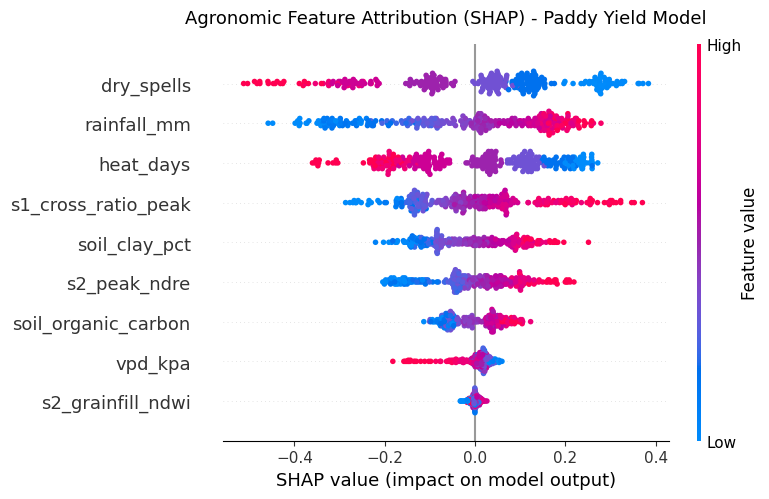

SHAP explainability plot generated and saved as 'paddy_yield_shap_importance.png'.


In [6]:
# Compute SHAP values for tree explainability
explainer = shap.TreeExplainer(model_median)
shap_values = explainer.shap_values(X_test)

# Plot Feature Importance & Directionality
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Agronomic Feature Attribution (SHAP) - Paddy Yield Model", fontsize=13, pad=15)
plt.tight_layout()
plt.savefig("paddy_yield_shap_importance.png", dpi=300, bbox_inches='tight')
plt.show()

print("SHAP explainability plot generated and saved as 'paddy_yield_shap_importance.png'.")

In [7]:
# Convert pandas dataframe with lat/lon into GeoDataFrame (WGS84 EPSG:4326)
geometry = [Point(xy) for xy in zip(test_df['longitude'], test_df['latitude'])]
gdf_paddy = gpd.GeoDataFrame(test_df, geometry=geometry, crs="EPSG:4326")

# Export to GeoJSON
output_geojson = "india_paddy_insurance_atlas.geojson"
gdf_paddy.to_file(output_geojson, driver="GeoJSON")

print(f"Spatial Atlas successfully exported: {output_geojson}")
print(f"Features exported: {len(gdf_paddy)} village clusters with 18 spatial attributes.")

Spatial Atlas successfully exported: india_paddy_insurance_atlas.geojson
Features exported: 300 village clusters with 18 spatial attributes.
